[Python, Visually](https://johnfisher-ai.github.io/Python-Visual-Guides/) &nbsp;&rsaquo;&nbsp; [GeoPandas, Deep Dive](https://johnfisher-ai.github.io/Python-Visual-Guides/geopandas-deep-dive.html)

# Shapely Geometries


## What you will be able to do

Build points, lines and polygons with Shapely, measure them, ask whether one contains or touches
another, read and write them as text, and spot a polygon that is not valid.

## The idea

### The problem

The **Why GeoPandas** notebook gave every station a point and joined it to a district polygon. Each
value in that geometry column is a Shapely object, and every spatial question GeoPandas answers is
answered by Shapely, one shape at a time or a whole column at once. A map of a weather station's
grounds shows what the questions are. The fence is a polygon with a pond inside it that is not part
of the grounds, the footpath is a line, and the mast and the gate are points. Is the mast inside the
fence? Does the footpath cross the hut? How long is the fence, and how much ground does it enclose?

Those questions have exact answers, but they are tedious to code by hand. A point that lies on the
fence is neither inside nor outside, a polygon can have holes, and Norway's outline is made of 31
polygons. Shapely knows the rules, so the questions become method calls.

### A formal definition

> A **geometry** is a shape described by coordinates. A **Point** is one position, a **LineString**
> is a sequence of positions joined by straight segments, and a **Polygon** is an area bounded by a
> closed ring, with any number of inner rings for its holes. **MultiPoint**, **MultiLineString** and
> **MultiPolygon** collect several of one kind into a single value. A **spatial predicate** such as
> `contains`, `within`, `intersects` or `touches` compares two geometries and returns `True` or
> `False`.

### Why it works that way

Shapely treats every geometry as having an interior, a boundary and an exterior, and each predicate
is a rule about how those parts of two shapes meet. A polygon contains a point only when the point is
in its interior, so a gate on the fence line is touched by the grounds and not contained by them. A
line can start on the boundary and still be contained, as long as no part of it leaves the polygon.

Shapely has no notion of units or of the Earth. Its arithmetic happens on a flat plane, so an area is
in the square of whatever the coordinates are in. The grounds below are drawn in meters, so their
area is in square meters. Norway's outline is in degrees, and its area in square degrees would be
meaningless, which is why the **Coordinate Reference Systems** notebook converts it first.

A polygon also has to be valid, meaning its rings do not cross themselves. Shapely builds an invalid
polygon without complaint, and its area then comes out wrong.

### Where this shows up

Every geometry column in this guide is an array of these objects, and the **Spatial Predicates**
notebook runs the same predicates over whole columns. The **Measuring Distance and Area** notebook
returns to area and length with real units.

### What this notebook covers

- a point, a line and a polygon with a hole, and what each one measures
- the grounds drawn as a map
- Norway as a MultiPolygon of 31 parts
- geometries written as text and read back
- predicates and distances between the shapes
- whole arrays of geometries at once
- three mistakes in building a geometry

### A first look

Before any of the detail, here is the whole idea in a few lines. There is nothing to run yet: read it,
and read the output underneath it. Everything from Setup onward is where you start running things.

```python
from shapely.geometry import Point, Polygon

field = Polygon([(0, 0), (4, 0), (4, 3), (0, 3)])
print(field.area, field.length)
print(field.contains(Point(1, 1)), field.contains(Point(5, 1)), field.touches(Point(4, 1)))
```

```
12.0 14.0
True False True
```

A 4 by 3 rectangle has an area of 12 and a perimeter of 14. It contains the point inside it and
touches the point on its edge, and the point outside it gives `False`.

## Setup

Two libraries for the table of named stations and the country outlines, Shapely for the shapes, and
Matplotlib for a drawing.

- `Path` finds the guide's copy of the country outlines, when the notebook runs beside it
- `pandas` holds the five named stations
- `geopandas` reads the outlines, converts Norway's to meters, and draws the grounds
- `shapely` measures, compares and converts geometries, and the cell prints its version and the
  version of GEOS, the C library that does the work
- `LineString`, `MultiPoint`, `Point` and `Polygon` are the geometry types this notebook builds
- `matplotlib.pyplot` draws the grounds

`countries` holds the outlines of Denmark, Finland, Norway, Russia and Sweden. Made with Natural
Earth. The outlines come from Natural Earth's 1:50m map of the world's countries, which is in the
public domain. `norway` is Norway's outline on its own. `weather_stations` is the five named stations
at their real positions. The station grounds in the worked examples are made up, drawn in meters from
the southwest corner of the fence.

In [1]:
from pathlib import Path

import pandas as pd
import geopandas as gpd
import shapely
from shapely.geometry import LineString, MultiPoint, Point, Polygon
import matplotlib.pyplot as plt

COUNTRIES_URL = ("https://raw.githubusercontent.com/johnfisher-ai/Python-Visual-Guides/main/data/nordic-countries.geojson")
local_copy = Path("../../data/nordic-countries.geojson")
countries = gpd.read_file(local_copy if local_copy.exists() else COUNTRIES_URL)


weather_stations = pd.DataFrame({
    "name": ["Bergen", "Oslo", "Svalbard", "Tromso", "Kirkenes"],
    "latitude": [60.39, 59.91, 78.22, 69.65, 69.73],
    "longitude": [5.32, 10.75, 15.65, 18.96, 30.05],
})


norway = countries.loc[countries["ADMIN"] == "Norway", "geometry"].iloc[0]
print("shapely", shapely.__version__, "| GEOS", shapely.geos_version_string, "| Norway is a",
      norway.geom_type, "of", len(norway.geoms), "parts")

shapely 2.2.0 | GEOS 3.14.1 | Norway is a MultiPolygon of 31 parts


## Worked examples

### A point

In [2]:
oslo = Point(10.75, 59.91)
print(oslo.geom_type, "| x:", oslo.x, "| y:", oslo.y)
print(oslo)

Point | x: 10.75 | y: 59.91
POINT (10.75 59.91)


A point holds an x and a y. Printing a geometry writes it as text, longitude first for a position on
the globe, since longitude is the east and west coordinate. A point has no area and no length.

### A line

In [3]:
footpath = LineString([(0, 40), (40, 40), (40, 60), (110, 60)])
print(footpath.geom_type, "|", len(footpath.coords), "coordinates")
print("length:", footpath.length, "m")
print("bounds:", footpath.bounds)

LineString | 4 coordinates
length: 130.0 m
bounds: (0.0, 40.0, 110.0, 60.0)


The footpath starts at the gate on the west fence, runs 40 m east, turns north for 20 m and runs
another 70 m east, 130 m in all. `bounds` is the smallest rectangle around the shape, as
`(min_x, min_y, max_x, max_y)`.

### A polygon with a hole

A `Polygon` takes the outer ring, then a list of inner rings. The outer ring here is the fence, 120 m
by 80 m, and the inner ring is a pond of 20 m by 20 m.

In [4]:
grounds = Polygon(
    [(0, 0), (120, 0), (120, 80), (0, 80)],
    holes=[[(80, 20), (100, 20), (100, 40), (80, 40)]],
)
print("area:", grounds.area, "m²")
print("perimeter of every ring:", grounds.length, "m")
print("fence alone:", grounds.exterior.length, "m |", len(grounds.interiors), "hole of",
      grounds.interiors[0].length, "m around")
print("centroid:", shapely.to_wkt(grounds.centroid, rounding_precision=1))

area: 9200.0 m²
perimeter of every ring: 480.0 m
fence alone: 400.0 m | 1 hole of 80.0 m around
centroid: POINT (58.7 40.4)


The fence encloses 9,600 m², and the pond's 400 m² are not part of the grounds, which leaves 9,200 m².
`length` adds every ring, the 400 m fence and the 80 m around the pond. The centroid, the shape's
center of mass, sits a little west of the middle, at x 58.7, because the pond takes area from the
east half. `to_wkt` with `rounding_precision=1` writes the coordinates to one decimal place.

### The grounds as a drawing

A hut and a mast complete the grounds. `shapely.box` makes a rectangle from its bounds. A GeoSeries
holds geometries of any kind, and its `plot` method draws them, which is the quickest way to check a
shape by eye.

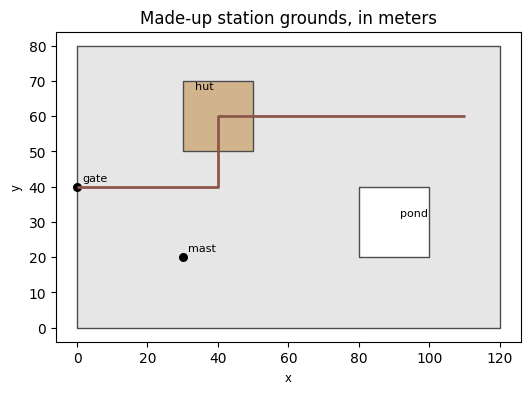

In [5]:
hut = shapely.box(30, 50, 50, 70)
mast = Point(30, 20)
gate = Point(0, 40)

fig, ax = plt.subplots(figsize=(6, 4.5))
gpd.GeoSeries([grounds]).plot(ax=ax, color="0.9", edgecolor="0.3")
gpd.GeoSeries([hut]).plot(ax=ax, color="tan", edgecolor="0.3")
gpd.GeoSeries([footpath]).plot(ax=ax, color="tab:brown", linewidth=2)
gpd.GeoSeries([mast, gate]).plot(ax=ax, color="black", markersize=30)
for label, point in [("mast", mast), ("gate", gate), ("hut", Point(32, 66)), ("pond", Point(90, 30))]:
    ax.annotate(label, (point.x, point.y), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.set_title("Made-up station grounds, in meters")
plt.show()

The pond is the white square inside the grounds, since a hole is not filled. The footpath leaves the
gate, turns north into the hut, leaves it heading east and ends 10 m short of the east fence.

### Many parts in one value

Norway's outline is a `MultiPolygon`, and `geoms` gives its parts one by one.

In [6]:
print(norway.geom_type, "|", len(norway.geoms), "parts |", shapely.get_num_coordinates(norway), "coordinates")
norway_m = countries.to_crs(25833).loc[countries["ADMIN"] == "Norway", "geometry"].iloc[0]
part_areas = sorted((part.area / 1e6 for part in norway_m.geoms), reverse=True)
print("largest parts, km²:", [round(area) for area in part_areas[:4]])
print("all parts, km²:", round(sum(part_areas)))

MultiPolygon | 31 parts | 1973 coordinates
largest parts, km²: [312895, 38807, 14769, 7038]
all parts, km²: 386897


The 31 parts are the mainland and its larger islands, Svalbard's islands among them. The mainland is
by far the largest part, 312,895 km², and the next, 38,807 km², is Svalbard's largest island. The
areas come from the outline converted to meters with `to_crs(25833)`, which the **Coordinate
Reference Systems** notebook explains.

A `MultiPoint` collects points the same way.

In [7]:
stations = MultiPoint(list(zip(weather_stations["longitude"], weather_stations["latitude"])))
print(len(stations.geoms), "points")
print(stations)

5 points
MULTIPOINT ((5.32 60.39), (10.75 59.91), (15.65 78.22), (18.96 69.65), (30.05 69.73))


### Geometries as text

The text a geometry prints is **WKT**, well-known text, a standard that databases and GIS programs
read too. `shapely.from_wkt` turns it back into a geometry.

In [8]:
text = shapely.to_wkt(grounds, rounding_precision=0)
print(text)
back = shapely.from_wkt(text)
turned = Polygon([(120, 0), (120, 80), (0, 80), (0, 0)], holes=[[(80, 20), (100, 20), (100, 40), (80, 40)]])
print("identical:", back == grounds, "| started at another corner, equals:", turned.equals(grounds),
      "| ==:", turned == grounds)

POLYGON ((0 0, 120 0, 120 80, 0 80, 0 0), (80 20, 100 20, 100 40, 80 40, 80 20))
identical: True | started at another corner, equals: True | ==: False


`==` is the exact test, the same coordinates in the same order, and the round trip passes it.
`equals` compares shapes, so the same fence written from another corner counts as equal to the
grounds by `equals` and not by `==`.

### Predicates

Each predicate takes another geometry and returns `True` or `False`.

In [9]:
print("grounds contains mast:     ", grounds.contains(mast))
print("mast within grounds:       ", mast.within(grounds))
print("grounds contains gate:     ", grounds.contains(gate))
print("grounds touches gate:      ", grounds.touches(gate))
print("grounds intersects gate:   ", grounds.intersects(gate))
print("grounds contains footpath: ", grounds.contains(footpath))
print("footpath crosses hut:      ", footpath.crosses(hut))
print("pond point within grounds: ", Point(90, 30).within(grounds))

grounds contains mast:      True
mast within grounds:        True
grounds contains gate:      False
grounds touches gate:       True
grounds intersects gate:    True
grounds contains footpath:  True
footpath crosses hut:       True
pond point within grounds:  False


`within` is `contains` with the two shapes swapped. The gate lies on the fence, so the grounds touch
and intersect it but do not contain it. The footpath starts at the same gate and still counts as
contained, because the rest of it runs through the interior and no part of it leaves the grounds. A
point in the pond is outside the grounds, since the hole is not part of the polygon. The footpath
crosses the hut, since it enters the hut's interior and leaves it again.

`distance` measures the shortest gap between two shapes, 0 when they meet.

In [10]:
print("mast to footpath:  ", mast.distance(footpath), "m")
print("pond point to grounds:", Point(90, 30).distance(grounds), "m")
print("gate to grounds:   ", gate.distance(grounds), "m")

mast to footpath:   20.0 m
pond point to grounds: 10.0 m
gate to grounds:    0.0 m


The mast is 20 m from the nearest point of the footpath. The point in the middle of the pond is 10 m
from the grounds, the distance to the pond's edge.

### Whole arrays at once

Shapely's functions also take arrays of geometries and return an array of answers, computed in GEOS
without a Python loop. GeoPandas uses them for every geometry column.

In [11]:
shapes = [grounds, footpath, mast, hut]
print("type:    ", shapely.get_type_id(shapes))
print("area:    ", shapely.area(shapes))
print("length:  ", shapely.length(shapes))
print("in grounds:", shapely.within(shapes, grounds))

type:     [3 1 0 3]
area:     [9200.    0.    0.  400.]
length:   [480. 130.   0.  80.]
in grounds: [ True  True  True  True]


The type ids are 3 for a polygon, 1 for a line and 0 for a point. A point and a line have no area,
and a point has no length. The last line tests every shape against the grounds in one call. The
grounds count as within themselves, since every part of a shape lies inside it.

## Your turn

Five tasks. Write your answer in the cell under each task and run it.

Try a task before you look at its answer. Reading a solution teaches you much less than
getting there yourself, even slowly.

When you are ready: [**open the solutions notebook**](https://colab.research.google.com/github/johnfisher-ai/Python-Visual-Guides/blob/main/notebooks/geopandas-deep-dive/02-shapely-geometries-solutions.ipynb).

**1.** Make a point for Tromso from `weather_stations`, print it as WKT, and print whether it is within `norway`.

In [12]:
# your code here

**2.** Build a `LineString` from Bergen to Oslo to Tromso, in that order, from `weather_stations`, and print how many coordinates it has and its bounds.

In [13]:
# your code here

**3.** Make a rectangle 30 m wide and 50 m tall with `shapely.box`, and print its area and its perimeter.

In [14]:
# your code here

**4.** Test which of the points (10, 70), (90, 30) and (130, 40) lie within `grounds`, and print a list of the answers.

In [15]:
# your code here

**5.** Count the parts of Norway's outline that measure more than 1,000 km², using `norway_m`.

In [16]:
# your code here

## Common errors

### `GEOSException: ParseException: Expected number but encountered end of stream`

A WKT string copied from a file or a web page and cut short.

In [17]:
shapely.from_wkt("POINT (10.75")

GEOSException: ParseException: Expected number but encountered end of stream

GEOS reads the text left to right and reaches the end while it still expects the latitude. The
message names what it expected, so check the text where it stops. A complete string, such as
`"POINT (10.75 59.91)"`, reads without error.

### `ValueError: A linearring requires at least 4 coordinates.`

In [18]:
Polygon([(0, 0), (120, 0)])

ValueError: A linearring requires at least 4 coordinates.

A polygon's ring needs at least three distinct corners, and Shapely closes it by repeating the first,
which makes four coordinates. Two positions describe a line, so build a `LineString` for them, or
give the polygon every corner. With a third corner the same call makes a triangle, half of the fenced
rectangle, 4,800 m².

In [19]:
print(Polygon([(0, 0), (120, 0), (120, 80)]).area)

4800.0


### No error, and an area of 0.0

In [20]:
bowtie = Polygon([(0, 0), (2, 2), (2, 0), (0, 2)])
print("area:", bowtie.area)
print("valid:", bowtie.is_valid, "|", shapely.is_valid_reason(bowtie))

area: 0.0
valid: False | Self-intersection[1 1]


The corners are listed in an order that makes the ring cross itself at (1, 1), so the shape is two
triangles drawn as one ring. Shapely builds it without complaint, and its area comes out as 0.0,
because the two triangles are traced in opposite directions and cancel. `is_valid` and
`is_valid_reason` find the fault. `shapely.make_valid` repairs it, here into a MultiPolygon of the two
triangles.

In [21]:
repaired = shapely.make_valid(bowtie)
print(repaired.geom_type, "| area:", repaired.area, "| valid:", repaired.is_valid)

MultiPolygon | area: 2.0 | valid: True


## Recap

- You can build points, lines and polygons, holes included, and read their area, length and bounds.
- You can take a MultiPolygon apart into its parts.
- You can write a geometry as WKT and read it back.
- You can test how two geometries meet with `contains`, `within`, `touches`, `intersects` and
  `crosses`, and measure the distance between them.
- You can check a polygon with `is_valid` and repair it with `make_valid`.

## What is next

**The GeoDataFrame** notebook puts geometries like these into a column of a table, and looks at what
pandas operations do to that column.

---

&#8592; **Previous:** [Why GeoPandas](https://colab.research.google.com/github/johnfisher-ai/Python-Visual-Guides/blob/main/notebooks/geopandas-deep-dive/01-why-geopandas.ipynb)  &nbsp;·&nbsp;  [GeoPandas, Deep Dive Notebooks](https://johnfisher-ai.github.io/Python-Visual-Guides/geopandas-deep-dive.html)  &nbsp;·&nbsp;  **Next:** [The GeoDataFrame](https://colab.research.google.com/github/johnfisher-ai/Python-Visual-Guides/blob/main/notebooks/geopandas-deep-dive/03-the-geodataframe.ipynb) &#8594;
